In [1]:
import subprocess
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout or "tidak ada nvidia-smi")

Tue Oct 27 13:11:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 2050      WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   49C    P0              7W /   50W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
import torch, torchvision, sys
print(sys.executable)
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("GPU terbaca:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("nama GPU:", torch.cuda.get_device_name(0))

d:\Data Mining\.venv\Scripts\python.exe
torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
GPU terbaca: True
nama GPU: NVIDIA GeForce RTX 2050


In [2]:
import os, numpy as np, pandas as pd, torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

df = pd.read_csv("split_ambang6.csv")
KELAS = sorted(df["label"].unique())          # calculus, caries, gingivitis
k2i = {k: i for i, k in enumerate(KELAS)}
df["y"] = df["label"].map(k2i)

hilang = [p for p in df["path"] if not os.path.exists(p)]
print("file hilang:", len(hilang))
print("kelas:", k2i)
print(df["split"].value_counts().to_string())

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

class Gigi(Dataset):
    def __init__(self, d, tf):
        self.p, self.y, self.tf = d["path"].tolist(), d["y"].tolist(), tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

BATCH = 16
dl = {}
for sp, tf in [("train", tf_train), ("val", tf_eval), ("test", tf_eval)]:
    sub = df[df["split"] == sp].reset_index(drop=True)
    dl[sp] = DataLoader(Gigi(sub, tf), batch_size=BATCH, shuffle=(sp == "train"), num_workers=0)

n_train = df[df["split"] == "train"]["y"].value_counts().sort_index().values
bobot = torch.tensor(n_train.sum() / (len(KELAS) * n_train), dtype=torch.float32)
print("jumlah train per kelas:", dict(zip(KELAS, n_train.tolist())))
print("bobot kelas:", dict(zip(KELAS, bobot.round(decimals=2).tolist())))

xb, yb = next(iter(dl["train"]))
print("bentuk batch:", tuple(xb.shape), "| label:", yb.tolist())
print("device:", device)

file hilang: 0
kelas: {'calculus': 0, 'caries': 1, 'gingivitis': 2}
split
train    2022
test      409
val       397
jumlah train per kelas: {'calculus': 414, 'caries': 463, 'gingivitis': 1145}
bobot kelas: {'calculus': 1.6299999952316284, 'caries': 1.4600000381469727, 'gingivitis': 0.5899999737739563}
bentuk batch: (16, 3, 224, 224) | label: [1, 2, 2, 2, 2, 0, 2, 1, 1, 0, 2, 2, 2, 2, 2, 2]
device: cuda


In [3]:
import time, torch.nn as nn
from torchvision import models
from sklearn.metrics import f1_score

weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
model = models.mobilenet_v2(weights=weights)
model.classifier[1] = nn.Linear(model.last_channel, len(KELAS))
model = model.to(device)

kriteria = nn.CrossEntropyLoss(weight=bobot.to(device))
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda")

def evaluasi(loader):
    model.eval()
    ys, ps, total = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast("cuda"):
                out = model(x)
                total += kriteria(out, y).item() * len(y)
            ys += y.tolist()
            ps += out.argmax(1).tolist()
    ys, ps = np.array(ys), np.array(ps)
    return total / len(ys), (ys == ps).mean(), f1_score(ys, ps, average="macro")

EPOCH = 8
terbaik, riwayat = -1, []
for ep in range(1, EPOCH + 1):
    t0 = time.time()
    model.train()
    tot, n = 0.0, 0
    for x, y in dl["train"]:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.autocast("cuda"):
            loss = kriteria(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        tot += loss.item() * len(y); n += len(y)
    vl, va, vf = evaluasi(dl["val"])
    riwayat.append({"epoch": ep, "loss_train": tot / n, "loss_val": vl,
                    "acc_val": va, "f1_val": vf})
    tanda = ""
    if vf > terbaik:
        terbaik = vf
        torch.save(model.state_dict(), "mobilenetv2_baseline.pt")
        tanda = "  <- terbaik, disimpan"
    print(f"epoch {ep}/{EPOCH} | loss train {tot/n:.3f} | loss val {vl:.3f} | "
          f"acc val {va:.3f} | F1 val {vf:.3f} | {time.time()-t0:.0f} dtk{tanda}")

pd.DataFrame(riwayat).to_csv("riwayat_baseline.csv", index=False)
print("selesai. F1 val terbaik:", round(terbaik, 3))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\HP VICTUS/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100.0%


epoch 1/8 | loss train 0.486 | loss val 0.379 | acc val 0.851 | F1 val 0.850 | 84 dtk  <- terbaik, disimpan
epoch 2/8 | loss train 0.178 | loss val 0.306 | acc val 0.861 | F1 val 0.856 | 29 dtk  <- terbaik, disimpan
epoch 3/8 | loss train 0.112 | loss val 0.215 | acc val 0.922 | F1 val 0.912 | 21 dtk  <- terbaik, disimpan
epoch 4/8 | loss train 0.078 | loss val 0.254 | acc val 0.884 | F1 val 0.881 | 19 dtk
epoch 5/8 | loss train 0.040 | loss val 0.200 | acc val 0.912 | F1 val 0.906 | 19 dtk
epoch 6/8 | loss train 0.045 | loss val 0.305 | acc val 0.872 | F1 val 0.866 | 19 dtk
epoch 7/8 | loss train 0.045 | loss val 0.311 | acc val 0.902 | F1 val 0.891 | 19 dtk
epoch 8/8 | loss train 0.048 | loss val 0.300 | acc val 0.897 | F1 val 0.892 | 19 dtk
selesai. F1 val terbaik: 0.912


akurasi uji: 0.914

              precision    recall  f1-score   support

    calculus      0.955     0.787     0.863        80
      caries      0.839     0.940     0.887       100
  gingivitis      0.939     0.948     0.943       229

    accuracy                          0.914       409
   macro avg      0.911     0.892     0.898       409
weighted avg      0.918     0.914     0.914       409

akurasi per kelas dan sumber:
                      mean  count
label      source                
calculus   kaggle    0.788     80
caries     kaggle    0.871     31
           roboflow  0.971     69
gingivitis kaggle    0.948    229

confusion matrix (baris = asli, kolom = prediksi):
            calculus  caries  gingivitis
calculus          63       6          11
caries             3      94           3
gingivitis         0      12         217


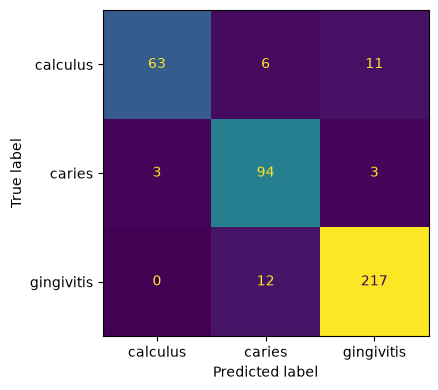

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("mobilenetv2_baseline.pt", map_location=device))
model.eval()

ys, ps = [], []
with torch.no_grad():
    for x, y in dl["test"]:
        out = model(x.to(device))
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()
ys, ps = np.array(ys), np.array(ps)

te = df[df["split"] == "test"].reset_index(drop=True)
assert len(te) == len(ys)
te["pred"] = [KELAS[i] for i in ps]
te["benar"] = te["label"] == te["pred"]

print("akurasi uji:", round(float(te["benar"].mean()), 3))
print()
print(classification_report(ys, ps, target_names=KELAS, digits=3))

print("akurasi per kelas dan sumber:")
print(te.groupby(["label", "source"])["benar"].agg(["mean", "count"]).round(3))

cm = confusion_matrix(ys, ps)
print()
print("confusion matrix (baris = asli, kolom = prediksi):")
print(pd.DataFrame(cm, index=KELAS, columns=KELAS))

os.makedirs("docs", exist_ok=True)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=ax, colorbar=False)
plt.tight_layout()
plt.savefig("docs/confusion_baseline.png", dpi=150)
plt.show()

te[["label", "source", "pred"]].to_csv("hasil_test_baseline.csv", index=False)